# Miniproyecto — Diseño de un pipeline ETL con fuentes heterogéneas

**Módulo:** Extracción, Transformación y Carga de Datos desde Fuentes Múltiples (5104)  
**Alumno/a:**  
**Fecha de entrega:**  

---

## ¿En qué consiste este miniproyecto?

El objetivo es que diseñes —sin implementarlo— un pipeline ETL completo que combine **al menos dos fuentes de datos heterogéneas** para producir un único dataset limpio y listo para ser analizado.

Una de las fuentes debe proporcionar datos **en tiempo real o con actualización frecuente** (cada pocos minutos u horas), y otra debe ser un **formulario** cuyos datos se acumulan a medida que los usuarios lo van rellenando. Cada fila del dataset final corresponde a una respuesta del formulario, enriquecida con los datos de la fuente en tiempo real recogidos en el momento en que se rellenó.

No vas a escribir código: vas a pensar, describir y diseñar. Eso es exactamente lo que hace un ingeniero/a de datos antes de ponerse a programar.


---
## Proyectos propuestos

Puedes elegir uno de los dos proyectos siguientes, o proponer el tuyo propio (consulta los requisitos al final de este apartado).

---

### Proyecto A — Polen y síntomas de alergia en Granada

Granada tiene una de las concentraciones de Polen de olivo más altas de Europa, especialmente entre abril y junio. Muchas personas no saben si sus síntomas (picor de ojos, estornudos, fatiga) están relacionados con el Polen o con otros factores.

La idea es recoger síntomas diarios de un grupo de personas mediante un formulario, y combinarlos automáticamente con los datos de calidad del aire y concentración de Polen del momento en que rellenaron el formulario. El dataset resultante permitiría estudiar si hay correlación entre el índice de Polen y la intensidad de los síntomas.

**Fuentes de datos disponibles:**

- **Formulario de síntomas** (Google Forms): el usuario indica cada día sus síntomas,   su medicación y cómo se encuentra en general.
- **API Open-Meteo Air Quality** (`https://air-quality-api.open-meteo.com/v1/air-quality`):   devuelve concentración de Polen de gramíneas, olivo y arizónica, además de PM2.5 y ozono,   actualizada cada hora, sin necesidad de clave API.

---

### Proyecto B — Rendimiento deportivo y condiciones ambientales

¿Entrenas peor cuando hace mucho calor? ¿La humedad afecta a tu resistencia? Este proyecto busca recoger registros de entrenamientos de un grupo de deportistas y cruzarlos con las condiciones meteorológicas del momento en que entrenaron.

El dataset final permitiría analizar si la temperatura, la humedad o el viento tienen impacto en el rendimiento percibido o en las métricas objetivas del entrenamiento.

**Fuentes de datos disponibles:**

- **Formulario de entrenamiento** (Google Forms): el deportista registra al terminar   el entrenamiento el tipo de deporte, duración, distancia, esfuerzo percibido (1-10)   y sensación general.
- **API Open-Meteo** (`https://api.open-meteo.com/v1/forecast`): temperatura, humedad   relativa, velocidad del viento, índice UV y precipitación, actualizada cada 15 minutos,   sin clave API.

---

### Proyecto C — Propuesta propia

Si tienes otra idea, puedes desarrollarla siempre que cumpla estos requisitos:

- Al menos **dos fuentes** de datos heterogéneas.
- Una fuente debe ser un **formulario** (Google Forms u otro).
- Otra fuente debe ser una **API pública** con datos que se actualicen al menos cada hora.
- El dataset final debe tener sentido: cada fila representa una observación real   enriquecida con datos externos del mismo instante.

Antes de desarrollarla, descríbela brevemente aquí para asegurarte de que cumple los requisitos:

*Si vas a proponer tu propio proyecto, descríbelo aquí en 5-6 líneas:*



---
## Mi elección

Indica qué proyecto has elegido y por qué (2-3 frases):

*Escribe aquí:*

He decidido elegir el proyecto de Rendimiento deportivo y condiciones ambientales.
Me parece el más interesante ya que es el que más se asemeja a mi vida cotidiana.


---
## 1. Descripción de las fuentes de datos

Para cada fuente de datos de tu proyecto, rellena una ficha como la siguiente. Si tu proyecto tiene más de dos fuentes, añade las fichas que necesites.


### Fuente 1 — Formulario

| Campo | Descripción |
|-------|-------------|
| **Nombre** | Formulario informativo sobre entrenamiento |
| **Tipo de fuente** | Formulario web (Google Forms) |
| **URL o acceso** | Se crea un formulario en Google Forms y se comparte el enlace.|
| **Formato de los datos** | Las respuestas se guardan en un Google Sheet y se descargan como CSV |
| **Frecuencia de actualización** | Cada vez que el usuario lo rellena |
| **Quién lo rellena** | Participantes del estudio, una vez al día |

**Campos del formulario** (lista todas las preguntas que incluirías):

| Campo | Tipo de dato | Ejemplo de valor |
|-------|-------------|------------------|
| Marca temporal (la pone Google Forms) | Fecha y hora | 15/05/2026 08:47:10 |
| Nombre_usuario| Texto | Josito |
| Edad | Número | 19 |
| Deporte | Texto | Correr al aire libre |
| Hora de inicio del entrenamiento | Fecha y hora | 15/05/2026 08:00 |
| Hora de fin del entrenamiento | Fecha y hora | 15/05/2026 08:45 |
| Duración del ejercicio (min) | Número | 45 |
| Distancia recorrida (km) | Número con decimales | 9 |
| Esfuerzo percibido (1-10) | Número | 4 |

La marca temporal es cuando se envía el formulario, que no tiene por qué ser justo al acabar de entrenar. Por eso se piden la hora de inicio y la de fin, que son las que se usan para buscar el clima. Google Forms pide la fecha y la hora por separado y el pipeline las junta.

Todos entrenamos en Granada, así que las coordenadas para la API son fijas (37.18, -3.60) y no hace falta preguntarlas.

*Edita las tablas con tus datos reales:*

### Fuente 2 — API en tiempo real

| Campo | Descripción |
|-------|-------------|
| **Nombre** | Open-Meteo Forecast API |
| **Tipo de fuente** | API REST pública |
| **URL base** | `https://api.open-meteo.com/v1/forecast` para las lecturas actuales y `https://historical-forecast-api.open-meteo.com/v1/forecast` para el histórico |
| **Formato de respuesta** | JSON |
| **Frecuencia de actualización** | Cada 15 minutos |
| **Autenticación necesaria** | No, no hace falta clave API |

**Parámetros de la petición** (qué le envías a la API para obtener los datos que necesitas):

| Parámetro | Valor | Para qué sirve |
|-----------------|------|----------------|
| latitude | 37.18 | Latitud de Granada |
| longitude | -3.60 | Longitud de Granada |
| minutely_15 | temperature_2m, relative_humidity_2m, wind_speed_10m, uv_index, precipitation | Variables que queremos, con una lectura cada 15 minutos |
| start_date y end_date | Día del entrenamiento | Día o días que cubre el entrenamiento, luego nos quedamos solo con las lecturas entre el inicio y el fin |
| timezone | Europe/Madrid | Para que las horas salgan en hora local, igual que en el formulario |

La URL completa sería:
`https://historical-forecast-api.open-meteo.com/v1/forecast?latitude=37.18&longitude=-3.60&start_date=2026-05-15&end_date=2026-05-15&minutely_15=temperature_2m,relative_humidity_2m,wind_speed_10m,uv_index,precipitation&timezone=Europe/Madrid`

**Campos de la respuesta que usarías** (no hace falta listarlos todos, solo los relevantes):

| Campo de la API | Tipo | Qué representa |
|-----------|-------|----------------|
| time | string (datetime ISO) | Hora de cada lectura de 15 minutos, sirve para quedarnos con las que caen entre el inicio y el fin |
| temperature_2m | float | Temperatura del aire a 2m de altura, en °C |
| relative_humidity_2m | int | Humedad relativa a 2m de altura, en % |
| wind_speed_10m | float | Velocidad del viento a 10m de altura, en km/h |
| uv_index | float | Índice ultravioleta |
| precipitation | float | Precipitación de los 15 minutos anteriores, en mm |

*Edita las tablas con tus datos reales:*

---
## 2. Diseño del dataset final

Describe el esquema del dataset que producirá tu pipeline. Cada fila representa una respuesta del formulario enriquecida con los datos de la API recogidos en el mismo instante.

### 2.1 Esquema de columnas

| Columna | Tipo | Origen | Descripción |
|---------|------|--------|-------------|
| id_respuesta | str | Formulario | Id que da Google Forms a cada respuesta, no cambia nunca |
| `timestamp` | datetime | Formulario | Fecha y hora en que se envió el formulario |
| Nombre_usuario | str | Formulario | Nombre del usuario que realiza el formulario |
| Edad | int | Formulario | Edad del usuario |
| Deporte | str | Formulario | Deporte que realiza el usuario |
| Inicio_entrenamiento | datetime | Formulario | Fecha y hora a la que empieza el entrenamiento |
| Fin_entrenamiento | datetime | Formulario | Fecha y hora a la que termina el entrenamiento |
| Duracion_ejercicio | int | Formulario | Duración del ejercicio en minutos |
| Distancia_recorrida | float | Formulario | Distancia que recorre el usuario en km |
| Esfuerzo_percibido | int | Formulario | Valoración del esfuerzo del usuario |
| Temperatura | float | API | Temperatura media del entrenamiento en grados |
| Humedad_relativa | float | API | % Humedad media del entrenamiento |
| Velocidad_viento | float | API | Velocidad media del viento en km/h |
| Indice_UV | float | API | Índice ultravioleta máximo del entrenamiento |
| Precipitacion | float | API | Precipitación total del entrenamiento en mm |
| N_lecturas_meteo | int | Pipeline | Número de lecturas de 15 minutos que se han usado |
| Variables_interpoladas | str | Pipeline | Variables con algún valor estimado por interpolación, vacío si no hay ninguna |
| Estado_meteo | str | Pipeline | ok, pendiente o ausente según se haya podido recuperar el clima |
| Motivo_meteo | str | Pipeline | Por qué está pendiente o ausente |
| Estado_calidad | str | Pipeline | ok, sospechoso o invalido según la validación de los datos del formulario |

*Edita la tabla con las columnas reales de tu dataset:*

### 2.2 Ejemplo de fila

Escribe cómo se vería una fila real (inventada) del dataset final, con valores concretos en cada columna:

```
timestamp          | col_form_1 | col_form_2 | ... | col_api_1 | col_api_2 | ...
2025-05-15 08:32   |    ...     |    ...     | ... |    ...    |    ...    | ...
```

*Escribe aquí tu ejemplo de fila con valores reales:*

```
id_respuesta | timestamp        | Nombre_usuario | Edad | Deporte              | Inicio_entrenamiento | Fin_entrenamiento | Duracion_ejercicio | Distancia_recorrida | Esfuerzo_percibido | Temperatura | Humedad_relativa | Velocidad_viento | Indice_UV | Precipitacion | N_lecturas_meteo | Variables_interpoladas | Estado_meteo | Motivo_meteo | Estado_calidad
ACYDBNh7...  | 2026-05-15 08:47 | Josito         | 19   | Correr al aire libre | 2026-05-15 08:00     | 2026-05-15 08:45  | 45                 | 9.0                 | 4                  | 18.4        | 56.5             | 4.2              | 3.5       | 0.0           | 4                |                        | ok           |              | ok
```

Temperatura, humedad y viento son la media de las 4 lecturas de 15 minutos entre las 08:00 y las 08:45, el UV es el máximo y la precipitación la suma.

### 2.3 Formatos de exportación

El dataset final se exportará en los siguientes formatos (indica al menos dos y justifica para qué serviría cada uno):

| Formato | Justificación |
|---------|---------------|
| CSV | Para compartir con investigadores que usan Excel o R, y para que los propios deportistas puedan revisar sus registros fácilmente |
| Parquet | Para análisis y procesamiento posterior con pandas o herramientas de Big Data: ocupa menos espacio, conserva los tipos de dato (int, datetime...) y se lee más rápido que el CSV en datasets grandes |

*Edita la tabla:*



---
## 3. Diseño del pipeline

Describe y dibuja el pipeline completo: cómo fluyen los datos desde las fuentes hasta el dataset final, pasando por la extracción, el almacenamiento intermedio, la limpieza y la combinación.

### 3.1 Descripción por etapas

Explica qué ocurre en cada etapa del pipeline. Sé concreto: no digas solo 'se limpian los datos', sino qué problema concreto se limpia y cómo.


**Etapa 1 — Extracción del formulario**

*Describe aquí cómo se obtienen los datos del formulario: con qué frecuencia se recogen, en qué formato llegan, cómo se accede a ellos programáticamente (ej: Google Sheets API, descarga CSV periódica, webhook...). ¿Qué ocurre si el usuario deja campos en blanco?*



*Escribe aquí:*

Al enviar el formulario, la respuesta se guarda en el Google Sheet vinculado al Form. Un Apps Script con un disparador al enviar avisa al pipeline y guarda en el Sheet el id que Google Forms da a esa respuesta. El pipeline descarga el CSV, así que los datos llegan en el momento en que el usuario rellena el formulario. El Form tiene todos los campos obligatorios y los rangos validados, por ejemplo el esfuerzo solo deja poner del 1 al 10, así que no llegan campos en blanco. Lo que no puede evitar el Form son los valores raros pero posibles, como 90 km en 45 minutos, de eso se encarga la etapa 4.

**Etapa 2 — Extracción de la API en tiempo real**

*Describe cómo se consulta la API: ¿cada cuánto tiempo? ¿Para cada nueva respuesta del formulario o de forma periódica e independiente? ¿Cómo se asocia cada lectura de la API al timestamp exacto de la respuesta del formulario? ¿Qué pasa si la API no responde o devuelve un error?*



*Escribe aquí:*

Cuando llega una respuesta nueva, el pipeline pide a Open-Meteo las lecturas de 15 minutos del día del entrenamiento y se queda solo con las que caen entre la hora de inicio y la de fin. Open-Meteo solo actualiza sus datos cada 15 minutos, así que no hay que pedirlas cada pocos segundos. Una sola lectura al terminar no representa todo el entrenamiento, porque el tiempo puede cambiar mientras se entrena, por eso se usan todas las del tramo.

Cada lectura se guarda en DB_API. Si la llamada falla o todavía no hay datos de ese tramo, la fila queda como pendiente y la revisa un proceso periódico (lo explico en la etapa 4). No se usa nunca otra lectura de otro momento para rellenar el hueco.

**Etapa 3 — Almacenamiento intermedio**

*¿Dónde y cómo se guardan los datos de cada fuente antes de combinarlos? Por ejemplo: ¿los datos del formulario se guardan en un CSV local, en una BD SQLite, en un Google Sheet? ¿Y los de la API? ¿Con qué nombre de fichero o tabla? ¿Se sobreescriben o se van acumulando?*



*Escribe aquí:*

Los datos se guardan en ficheros locales, no en la nube, para no depender de que haya conexión en el momento de leerlos.

- DB_Form es una copia completa del CSV del Sheet. Se sobrescribe en cada ciclo pero no se pierde nada, porque el Sheet es el que va acumulando todas las respuestas.
- DB_API guarda las lecturas obtenidas de la API y se van acumulando. Una lectura no se guarda dos veces si coinciden su timestamp y su ubicación.
- result_DB es el cruce de formulario y API, con una fila por entrenamiento. Tampoco se sobrescribe. Solo se añaden las respuestas cuyo id_respuesta no esté ya, para no duplicar filas aunque se descargue otra vez todo el DB_Form. Las filas pendientes se completan después, actualizando esa fila.

result_DB es el dataset del análisis final, por eso necesita conservar todo el histórico.

**Etapa 4 — Limpieza y validación**

*Lista al menos 4 problemas de calidad concretos que podrían aparecer en tus datos y cómo los resolverías. Por ejemplo: timestamps en formato incorrecto, valores fuera de rango, respuestas duplicadas del formulario, campos de la API ausentes para ciertos horarios...*

| Problema | Fuente afectada | Por qué es un problema | Cómo se resuelve |
|----------|----------------|------------------------|------------------|
| Datos exagerados | Formulario | Un dato imposible distorsiona las medias y la relación con el clima, pero uno extremo real sí aporta información | El dato original no se toca nunca. Se detecta con límites por deporte, porque la velocidad que vale para correr no vale para ciclismo, y se marca como sospechoso. Si se confirma que es un error, se pone como invalido en el dataset limpio y se excluye del análisis, pero la fila sigue con su id_respuesta y su dato original. Si es raro pero real, se queda. No se cambia por la mediana porque eso falsea el dataset |
| Problemas en la conexión | API | Sin lecturas no hay clima para esa fila | La fila queda como pendiente. Un proceso periódico, por ejemplo cada hora, revisa las filas pendientes y vuelve a pedir las lecturas de su tramo. Si lo consigue, completa la fila y pasa a ok. Si tras unos días sigue sin poder, queda como ausente con su motivo. No se rellena con lecturas de otro momento |
| Valores ausentes | API | Falta alguna lectura de 15 minutos, y rellenarla mal inventaría clima que no existió | Con temperatura, humedad y viento, si falta una lectura suelta se interpola entre la anterior y la siguiente. Eso es una estimación y no una medición, así que la variable se apunta en Variables_interpoladas. La lluvia no se interpola, se pide otra vez o queda ausente |
| Respuestas duplicadas | Formulario | La misma respuesta contada dos veces pesa más en el análisis | Cada respuesta tiene el id que le da Google Forms, que es único y no cambia. Si llega otra vez un id que ya está en result_DB, no se añade. Que dos respuestas tengan el mismo timestamp no las hace duplicadas, porque varios usuarios pueden enviar a la vez |

*Edita la tabla:*

**Etapa 5 — Combinación (join) y producción del dataset final**

*Explica cómo se combinan los datos del formulario con los de la API: ¿qué campo se usa para hacer el join (timestamp, coordenadas geográficas...)? ¿Qué pasa si no hay dato de la API exactamente en ese instante: se usa el más cercano en el tiempo, se interpola, se descarta la fila? ¿En qué formato se guarda el dataset final y dónde?*



*Escribe aquí:*

El cruce se hace por tiempo, usando la hora de inicio y la de fin del entrenamiento. A cada respuesta se le asocian todas las lecturas de la API cuyo time cae entre las dos horas, y de ellas se calcula una sola fila: media de temperatura, humedad y viento, máximo del UV y suma de la precipitación. En N_lecturas_meteo se guarda cuántas se han usado. Si el entrenamiento es tan corto que no cae ninguna lectura, se coge la más cercana al punto medio. Las dos fuentes van en hora de Madrid para poder compararlas directamente.

Si no hay lecturas porque falló la conexión o todavía no hay datos de ese tramo, la fila queda como pendiente y el proceso de la etapa 4 lo vuelve a intentar. Si al final no se consigue, el clima queda ausente con su motivo, pero la fila no se descarta, porque perder una respuesta entera es peor que tenerla sin clima.

Después la fila se añade a result_DB, que va acumulando una fila por entrenamiento y no se sobrescribe, a diferencia de DB_Form. El dataset final se exporta en CSV y Parquet, tal como se definió en el apartado 2.3.

### 3.2 Grafo del pipeline

A continuación tienes el código para dibujar un grafo dirigido del pipeline con `networkx` y `matplotlib`. Modifica los nodos y las aristas para que representen exactamente tu pipeline (cambia los nombres, añade o elimina nodos según las etapas que hayas descrito arriba).

Cada nodo representa un componente del pipeline (fuente, almacén intermedio, proceso de transformación, dataset final). Cada arista representa el flujo de datos.


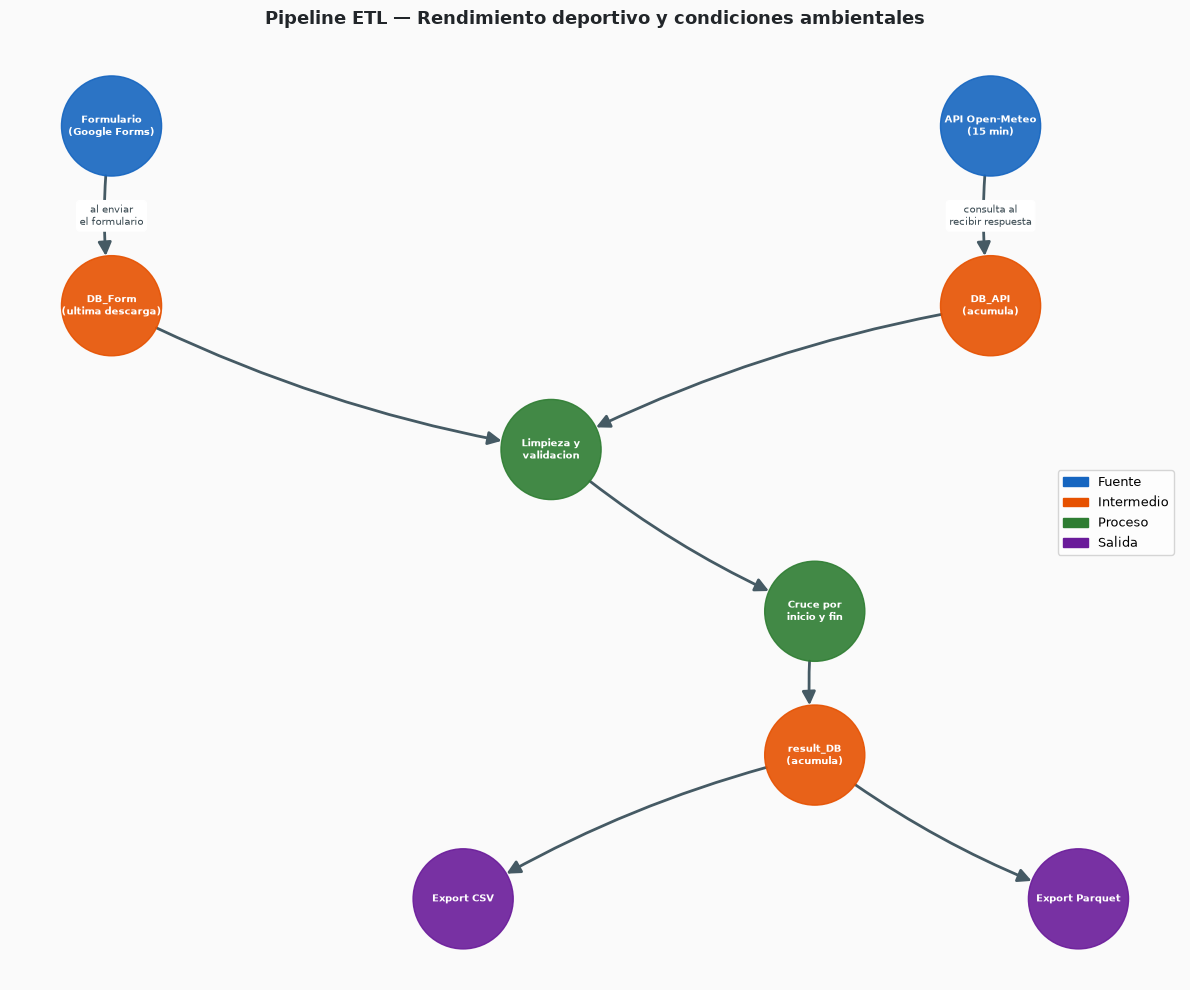

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

G = nx.DiGraph()

# ── NODOS ────────────────────────────────────────────────────────────────
# Modifica estas listas con los nodos de TU pipeline
# Grupos: 'fuente', 'intermedio', 'proceso', 'salida'
nodos = [
    # (nombre_nodo,              grupo)
    ('Formulario\n(Google Forms)',  'fuente'),
    ('API Open-Meteo\n(15 min)', 'fuente'),
    ('DB_Form\n(ultima descarga)',  'intermedio'),
    ('DB_API\n(acumula)',           'intermedio'),
    ('Limpieza y\nvalidacion',      'proceso'),
    ('Cruce por\ninicio y fin', 'proceso'),
    ('result_DB\n(acumula)',        'intermedio'),
    ('Export CSV',                  'salida'),
    ('Export Parquet',              'salida'),
]

# ── ARISTAS ──────────────────────────────────────────────────────────────
# (origen, destino, etiqueta opcional)
aristas = [
    ('Formulario\n(Google Forms)',  'DB_Form\n(ultima descarga)',  'al enviar\nel formulario'),
    ('API Open-Meteo\n(15 min)', 'DB_API\n(acumula)',         'consulta al\nrecibir respuesta'),
    ('DB_Form\n(ultima descarga)',  'Limpieza y\nvalidacion',      ''),
    ('DB_API\n(acumula)',           'Limpieza y\nvalidacion',      ''),
    ('Limpieza y\nvalidacion',      'Cruce por\ninicio y fin', ''),
    ('Cruce por\ninicio y fin', 'result_DB\n(acumula)', ''),
    ('result_DB\n(acumula)',        'Export CSV',                   ''),
    ('result_DB\n(acumula)',        'Export Parquet',               ''),
]

# ── COLORES POR GRUPO ────────────────────────────────────────────────────
colores_grupo = {
    'fuente':      '#1565C0',
    'intermedio':  '#E65100',
    'proceso':     '#2E7D32',
    'salida':      '#6A1B9A',
}
color_nodo = {n: colores_grupo[g] for n, g in nodos}

G.add_nodes_from([n for n, _ in nodos])
G.add_edges_from([(o, d) for o, d, _ in aristas])

# ── LAYOUT ───────────────────────────────────────────────────────────────
pos = {
    'Formulario\n(Google Forms)':   (0, 4.6),
    'API Open-Meteo\n(15 min)': (4, 4.6),
    'DB_Form\n(ultima descarga)':   (0, 2.6),
    'DB_API\n(acumula)':            (4, 2.6),
    'Limpieza y\nvalidacion':       (2, 1.0),
    'Cruce por\ninicio y fin': (3.2, -0.8),
    'result_DB\n(acumula)':         (3.2, -2.4),
    'Export CSV':                   (1.6, -4),
    'Export Parquet':               (4.4, -4),
}

fig, ax = plt.subplots(figsize=(12, 10))
fig.patch.set_facecolor('#FAFAFA')
ax.set_facecolor('#FAFAFA')

nx.draw_networkx_nodes(G, pos, ax=ax,
    node_color=[color_nodo[n] for n in G.nodes()],
    node_size=5200, alpha=0.9)

nx.draw_networkx_labels(G, pos, ax=ax,
    font_color='white', font_size=7, font_weight='bold')

nx.draw_networkx_edges(G, pos, ax=ax,
    edge_color='#455A64', arrows=True,
    arrowsize=20, width=2,
    connectionstyle='arc3,rad=0.08', node_size=5200)

etiquetas_aristas = {(o, d): lbl for o, d, lbl in aristas if lbl}
nx.draw_networkx_edge_labels(G, pos, etiquetas_aristas, ax=ax,
    font_size=7, font_color='#37474F', rotate=False)

leyenda = [mpatches.Patch(color=c, label=g.capitalize())
           for g, c in colores_grupo.items()]
ax.legend(handles=leyenda, loc='center right', fontsize=9)
ax.set_title('Pipeline ETL — ' + 'Rendimiento deportivo y condiciones ambientales',
             fontsize=13, fontweight='bold', color='#212529', pad=15)
ax.axis('off')
plt.tight_layout()
plt.show()

*(Si has modificado el grafo pero el layout automático no queda bien, descomenta el bloque `pos = { ... }` del código y ajusta las coordenadas de cada nodo manualmente hasta que quede claro y legible.)*


---
## 4. Limitaciones y mejoras futuras

Todo pipeline tiene limitaciones. Reflexiona sobre las tuyas y responde:

1. **¿Qué pasaría si la API dejara de estar disponible durante varios días?** ¿Cómo afectaría eso al dataset? ¿Cómo lo manejarías?

2. **¿Qué sesgo podría tener tu dataset?** Por ejemplo: ¿quién rellena el formulario? ¿Es una muestra representativa de la población que te interesa?

3. **¿Qué añadirías si tuvieras más recursos?** Por ejemplo: más fuentes de datos, mayor frecuencia de muestreo, un sistema de alertas automáticas...

*Responde aquí:*



*Escribe aquí tus respuestas:*

1. Si la API dejara de estar disponible varios días: las filas de esos días se quedarían sin datos climáticos. Esas filas se marcarían como pendientes en vez de rellenarlas con un dato inventado. Las respuestas del formulario no se perderían (se siguen guardando en DB_Form igualmente), y cuando la API volviera a funcionar se podría intentar completar esos huecos consultando el histórico de Open-Meteo, que sí permite pedir datos de fechas pasadas.

2. Sesgo del dataset: el principal es quién rellena el formulario. Si los participantes son conocidos míos o gente de un mismo grupo de edad y nivel físico, el dataset no representaría al deportista medio, estaría sesgado hacia ese perfil concreto y hacia los deportes que practica ese grupo (sesgo de muestra). También hay sesgo de autoinforme: el esfuerzo percibido (1-10) es subjetivo y cada persona lo valora de forma distinta, así que no es directamente comparable entre usuarios.

3. Con más recursos: añadiría una fuente de datos objetiva, como un pulsómetro o smartwatch conectado por API, para no depender solo del esfuerzo percibido. También ampliaría el número de participantes para que la muestra sea más representativa, y añadiría un sistema de alertas que marque entrenamientos con valores claramente atípicos (por ejemplo, una distancia o duración imposible) para revisarlos antes de que entren en result_DB.